# Лабораторная работа 8. Классификация изображений CIFAR-10

Короткий профиль запускает обе модели на общем разбиении и сохраняет матрицы ошибок.
Для полного опыта смените профиль на full. Полный скрипт находится в соседней папке Python_Code.

In [1]:
from pathlib import Path
import sys
here = Path.cwd().resolve()
candidates = [entry for path in (here, *here.parents)
              for entry in (path, path / 'Deep_Learning_Textbook')]
book = next(entry for entry in candidates if (entry / 'Python_Code/Chapter_08').is_dir())
sys.path.insert(0, str(book / 'Python_Code/Chapter_08'))
from cifar_classification import main

import os
from tempfile import gettempdir
folder = Path(os.environ.get('CIFAR_TEXTBOOK_DIR', Path(gettempdir()) / 'cifar10-textbook'))
# После первого получения официальных данных этот запуск работает из локального кэша.
arguments = ['--data-dir', str(folder), '--profile', 'short', '--seed', '42']
if not (folder / 'cifar-10-batches-py').is_dir():
    arguments.append('--download')

## Обучение и тест

Следите за валидационной метрикой во время выбора эпохи. Сумма элементов каждой матрицы должна совпадать с размером теста.

In [2]:
reports = main(arguments)

numeric_ce=1.407605964->1.307353637 gradient=[[0.6652409557748218, -0.7552715289452023, 0.09003057317038043]]


torch=2.10.0+cpu profile=short train=800 val=200 test=200
plain


epoch=1 train_ce=2.280191 val_accuracy=0.175000 val_macro_f1=0.100832
best_epoch=1 val_macro_f1=0.100832 test_accuracy=0.240000 test_macro_f1=0.179965
12 1 0 0 1 0 0 0 1 5
2 8 0 0 1 0 2 0 0 7
5 4 0 0 2 0 2 0 0 7
3 4 0 0 3 0 5 0 0 5
2 1 0 0 2 0 4 0 0 11
5 1 0 0 4 2 0 0 1 7
0 6 0 0 1 0 5 0 0 8
3 2 0 0 4 0 3 0 0 8
6 0 0 0 0 0 1 0 3 10
1 3 0 0 0 0 0 0 0 16
horizontal_flip


epoch=1 train_ce=2.282085 val_accuracy=0.175000 val_macro_f1=0.113904
best_epoch=1 val_macro_f1=0.113904 test_accuracy=0.230000 test_macro_f1=0.167671
7 2 0 0 0 1 0 0 3 7
1 9 0 0 0 0 2 0 0 8
5 4 0 0 1 0 2 0 0 8
2 4 1 0 1 0 6 0 0 6
2 1 0 1 0 0 5 0 0 11
3 2 0 1 2 1 0 0 0 11
0 6 0 0 0 0 7 0 0 7
2 4 0 0 1 0 4 0 0 9
3 1 0 0 0 0 1 0 5 10
0 3 0 0 0 0 0 0 0 17


## Независимая сверка

Строки соответствуют истинным классам, столбцы — прогнозам. Для каждого класса F1 равна удвоенному диагональному элементу, делённому на сумму строки и столбца. Усредняем по классам с одинаковым весом.

In [3]:
for name, report in reports.items():
    m = report['matrix']
    n = len(m)
    accuracy = sum(m[i][i] for i in range(n)) / sum(map(sum, m))
    f1 = sum(2*m[i][i] / max(1, sum(m[i]) + sum(row[i] for row in m))
             for i in range(n)) / n
    assert abs(accuracy - report['accuracy']) < 1e-6
    assert abs(f1 - report['macro_f1']) < 1e-6
    print(f'Сверено {name}: accuracy={accuracy:.4f}, macro-F1={f1:.4f}')

Сверено plain: accuracy=0.2400, macro-F1=0.1800
Сверено horizontal_flip: accuracy=0.2300, macro-F1=0.1677


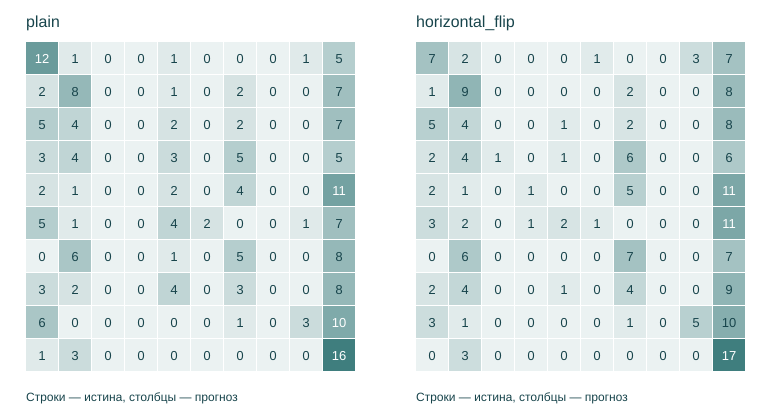

In [4]:
from html import escape
from IPython.display import SVG, display

n = len(next(iter(reports.values()))['matrix'])
size = 33
step = n * size + 60
width = 2 * step
height = n * size + 90
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" '
         f'viewBox="0 0 {width} {height}" role="img" aria-label="Две матрицы ошибок">',
         '<rect width="100%" height="100%" fill="white"/>']
for k, (name, report) in enumerate(reports.items()):
    base = k * step + 26
    matrix = report['matrix']
    scale = max(max(row) for row in matrix)
    parts.append(f'<text x="{base}" y="27" font-family="Arial" font-size="16" fill="#17444B">{escape(name)}</text>')
    for i, row in enumerate(matrix):
        for j, val in enumerate(row):
            x, y = base + size*j, 42 + size*i
            opacity = 0.10 + 0.85 * val / scale
            parts.append(f'<rect x="{x}" y="{y}" width="{size-1}" height="{size-1}" fill="#357878" opacity="{opacity:.3f}"/>')
            color = 'white' if opacity > .6 else '#17444B'
            parts.append(f'<text x="{x+16}" y="{y+21}" text-anchor="middle" font-family="Arial" font-size="13" fill="{color}">{val}</text>')
    parts.append(f'<text x="{base}" y="{height-19}" font-family="Arial" font-size="12" fill="#17444B">Строки — истина, столбцы — прогноз</text>')
parts.append('</svg>')
display(SVG(''.join(parts)))

## Задание

Объясните две крупнейшие внедиагональные ячейки. Сравните короткий и полный профили по числу примеров и эпох. Укажите, какие выводы можно делать только на общем тесте.